In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("heart.csv")

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
X = df.select_dtypes(include="number").drop(
    columns=["HeartDisease"],
    errors="ignore"
)


X = X.loc[:, X.nunique() > 1]


X = X.dropna()

print("Features:", list(X.columns))
print("Shape:", X.shape)

Features: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Shape: (918, 6)


In [4]:
X = (X - X.mean()) / X.std()

X.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak
0,-1.432359,0.410685,0.824621,-0.551041,1.382175,-0.831979
1,-0.478223,1.490940,-0.171867,-0.551041,0.753746,0.105606
2,-1.750404,-0.129442,0.769768,-0.551041,-1.524307,-0.831979
3,-0.584238,0.302660,0.138964,-0.551041,-1.131539,0.574398
4,0.051853,0.950812,-0.034736,-0.551041,-0.581664,-0.831979


# Manually R-squared calculate

In [5]:
def manual_r2(y, X_other):

    # Intercept add karvo
    X_other = np.column_stack([
        np.ones(len(X_other)),
        X_other
    ])

    y = np.array(y)


    beta = np.linalg.pinv(X_other) @ y

    # Predicted values
    y_pred = X_other @ beta

    # R-squared calculate 
    ss_total = np.sum((y - np.mean(y)) ** 2)
    ss_residual = np.sum((y - y_pred) ** 2)

    r2 = 1 - (ss_residual / ss_total)

    return max(0, min(1, r2))

# Dareka feature in the VIF calculate 

In [6]:
results = []

for feature in X.columns:

    y = X[feature]

    other_features = X.drop(columns=[feature])

    r2 = manual_r2(y, other_features.values)

    if r2 >= 1 - 1e-12:
        vif = np.inf
    else:
        vif = 1 / (1 - r2)

    results.append({
        "Feature": feature,
        "R-Squared": r2,
        "VIF": vif
    })

vif_df = pd.DataFrame(results)

vif_df = vif_df.sort_values(
    by="VIF", ascending=False
)

display(vif_df.round(3))

,Feature,R-Squared,VIF
0,Age,0.238,1.312
4,MaxHR,0.194,1.240
2,Cholesterol,0.135,1.157
3,FastingBS,0.101,1.113
1,RestingBP,0.093,1.103
5,Oldpeak,0.088,1.097


In [7]:
def interpret_vif(vif):

    if vif < 5:
        return "Low multicollinearity"

    elif vif < 10:
        return "Moderate multicollinearity"

    else:
        return "High multicollinearity"


vif_df["Interpretation"] = vif_df["VIF"].apply(
    interpret_vif
)

display(vif_df)

,Feature,R-Squared,VIF,Interpretation
0,Age,0.238081,1.312476,Low multicollinearity
4,MaxHR,0.193650,1.240156,Low multicollinearity
2,Cholesterol,0.135492,1.156728,Low multicollinearity
3,FastingBS,0.101389,1.112829,Low multicollinearity
1,RestingBP,0.093078,1.102631,Low multicollinearity
5,Oldpeak,0.088047,1.096548,Low multicollinearity


# VIF graph

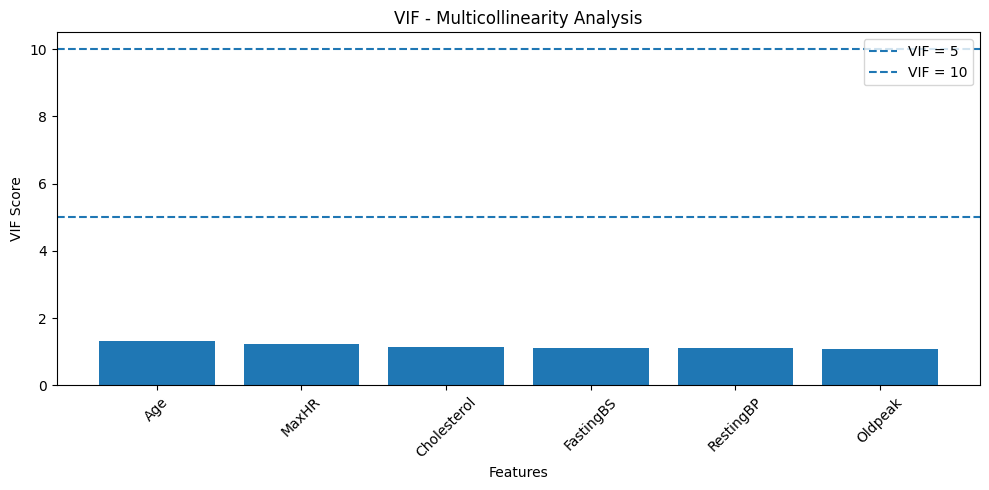

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(vif_df["Feature"], vif_df["VIF"])

plt.axhline(5, linestyle="--", label="VIF = 5")
plt.axhline(10, linestyle="--", label="VIF = 10")

plt.title("VIF - Multicollinearity Analysis")
plt.xlabel("Features")
plt.ylabel("VIF Score")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
print("MULTICOLLINEARITY ANALYSIS")

for _, row in vif_df.iterrows():
    print(
        f'{row["Feature"]}: VIF = {row["VIF"]:.2f} '
        f'-> {row["Interpretation"]}'
    )

print("\nConclusion:")

if (vif_df["VIF"] >= 5).any():
    print("Some features may have multicollinearity.")
else:
    print("No strong multicollinearity detected using VIF >= 5.")

MULTICOLLINEARITY ANALYSIS
Age: VIF = 1.31 -> Low multicollinearity
MaxHR: VIF = 1.24 -> Low multicollinearity
Cholesterol: VIF = 1.16 -> Low multicollinearity
FastingBS: VIF = 1.11 -> Low multicollinearity
RestingBP: VIF = 1.10 -> Low multicollinearity
Oldpeak: VIF = 1.10 -> Low multicollinearity

Conclusion:
No strong multicollinearity detected using VIF >= 5.
